# Lab 3: learning from a checker

**RLHF course, session 3 · Pegah Alizadeh**

This lab follows Chapter 6 of Nathan Lambert's [RLHF book](https://rlhfbook.com) and its
[suggested experiment](https://rlhfbook.com/c/06-policy-gradients#suggested-experiments), which asks for *"a small reasoning-gym policy-gradient config that
runs on a sub-1B Qwen model and reports the same group-contrast diagnostics"*. It is adapted from the book's
[`code/policy_gradients`](https://github.com/natolambert/rlhf-book/tree/main/code/policy_gradients) example.

**The task:** count how many times a letter appears in a short text, the "how many r's in strawberry?" problem.

**The question of the lab:** why do we need reinforcement learning at all? For this task we have **no examples of good
answers** to imitate (Lab 1), and **no comparisons** to fit a reward model to (Lab 2). We only have a **checker**: a
function that says whether a final answer is right. RL is the method that can learn from that alone.

| Part | What you do | Time |
|---|---|---|
| 1 | Meet the task and its checker | 5 min |
| 2 | The model can already do it, sometimes: pass@k (exercise A) | 15 min |
| 3 | Group advantages (exercise B) and the policy-gradient loss (exercise C) | 15 min |
| 4 | Train with GRPO | 20 min (it runs while you discuss) |
| 5 | What changed, and what didn't | 15 min |

If you get stuck, each exercise has a hint and a solution you can open. The aim is to understand the steps, so use them.

**Sources.** Lambert, Chapter 6: [GRPO](https://rlhfbook.com/c/06-policy-gradients#group-relative-policy-optimization-grpo),
[RLOO](https://rlhfbook.com/c/06-policy-gradients#reinforce-leave-one-out-rloo), [Example: GRPO](https://rlhfbook.com/c/06-policy-gradients#example-grpo) and
[Loss aggregation](https://rlhfbook.com/c/06-policy-gradients#loss-aggregation-tradeoffs). Lambert, Chapter 7,
[Common practices in training reasoning models](https://rlhfbook.com/c/07-reasoning#common-practices-in-training-reasoning-models). The task comes from
[reasoning-gym](https://github.com/open-thought/reasoning-gym), which the book's code uses. The statistical analyses in
Parts 2 and 5 were written for this course.

## The big picture

InstructGPT's recipe has three steps (Lecture 2, "Where we are: InstructGPT's three steps"). Lab 1 was step 1 and Lab 2
was step 2. **Today is step 3:**

1. **Instruction tuning:** teach a base model to answer (Lab 1)
2. **Reward model:** learn a score $r(x, y)$ from comparisons (Lab 2)
3. **Reinforcement learning:** train the model to write responses with a high reward. **This is today's lab.**

In step 3, the reward usually comes from the reward model of step 2. Today it comes from a **checker** instead: this is
**RL with verifiable rewards** (RLVR), the method behind reasoning models such as DeepSeek R1.

One round of the algorithm, **GRPO**, from the lecture:

1. **Sample** a few prompts, and **generate $K$ responses** to each with the current model
2. **Score** every response with the checker: 1 if the final answer is right, 0 otherwise
3. **Compare within each group:** a response's **advantage** is its reward relative to the other responses to the same
   prompt
4. **Update:** raise the probability of responses with a positive advantage, lower the others

The model only ever learns from **its own attempts**. If it never gets a prompt right, there is nothing to learn from.

### Key words

| Word | Meaning |
|---|---|
| **Rollout** | One response generated by the model during training |
| **Group** | The $K$ responses to the same prompt |
| **Verifiable reward** | A reward computed by a program, such as checking an answer, instead of by a learned model |
| **Advantage** | How much better a response did than the others in its group |
| **pass@k** | The probability that at least one of $k$ attempts is correct |
| **Reference model** | A frozen copy of the model before training, to measure how far training has moved it |

## Reminder: GRPO, from the lecture

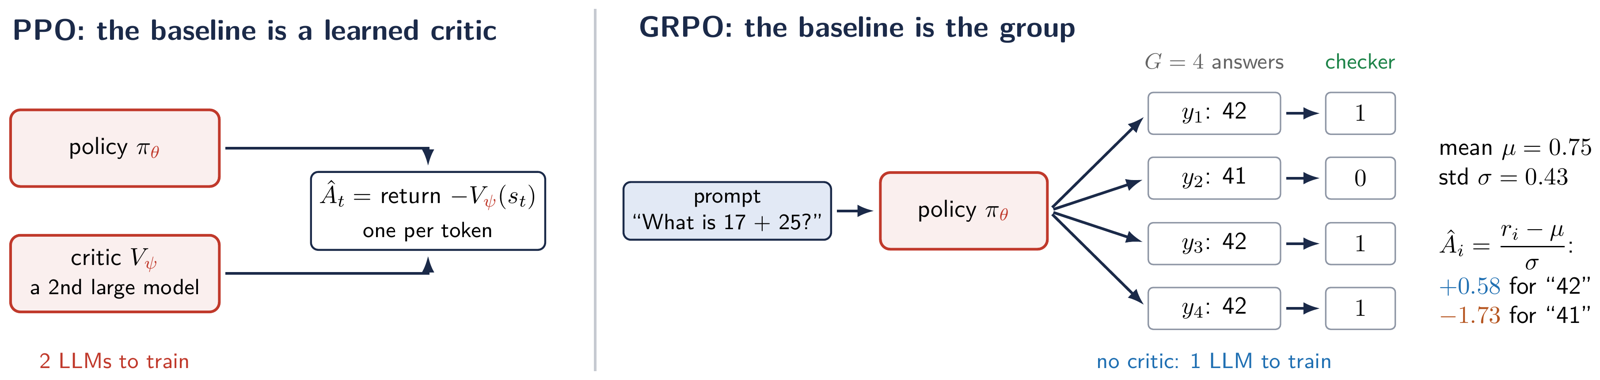

**The idea.** PPO compares each response with a **learned critic**, a second large model. GRPO drops the critic and
compares each response with **the other responses to the same prompt**. Above: 4 answers to *What is 17 + 25?*, checked
1, 0, 1, 1; the wrong one is pushed down, the right ones up.

**The advantage** of response $i$ in a group of $K$ (you write it in **exercise B**):

$$
\hat A_i = \frac{r_i - \mathrm{mean}(r_1, \ldots, r_K)}{\mathrm{std}(r_1, \ldots, r_K)}
$$

Every token of response $i$ gets the same $\hat A_i$.

**The update** (you write the loss in **exercise C**): raise $\log \pi_\theta$ of the tokens of responses with
$\hat A_i > 0$, lower it for $\hat A_i < 0$:

$$
\text{loss} = -\frac{1}{K}\sum_{i=1}^{K} \frac{1}{|y_i|} \sum_{t=1}^{|y_i|} \hat A_i \, \log \pi_\theta(y_{i,t} \mid x, y_{i,<t})
$$

This is GRPO's objective from the lecture with the clipping and the KL left out: with **one** update per batch the ratio
$\rho$ is 1, so clipping never acts, and here $\beta = 0$, as in the book's GRPO config. Part 3 explains both.

## Before you start

- **Colab:** Runtime → Change runtime type → **T4 GPU**.
- **Kaggle:** Settings → Accelerator → **GPU T4 x2**. Turn on **Internet** in the same panel.
- If you have no GPU, ask to pair with a neighbor.
- **Out of memory?** Restart the session (Colab: Runtime → Restart session; Kaggle: Run → Restart & clear cell outputs), then run all the cells again from the top.

**This cell:** installs `transformers` (the language model and its tokenizer) and `reasoning-gym` (the task generator and its checker), only if they are missing or too old.

**You should see:** nothing, or a few lines from pip. Red "dependency resolver" warnings are harmless.

In [ ]:
# Colab and Kaggle already include PyTorch. This installs the other libraries only if they are missing or too old,
# so it usually takes a few seconds. (transformers 4.56 or later is needed for the dtype= argument used below.)
%pip install -q "transformers>=4.56" reasoning-gym

**This cell:** loads the libraries: `torch` (tensors and training), `transformers` (the model), `reasoning_gym` (the task) and `matplotlib` (plots). Then it checks whether a GPU is available.

**You should see:** `Device: Tesla T4`. If you see `CPU`, change the runtime type (see "Before you start").

In [ ]:
import copy
import gc
import math
import random
import re
import time

import matplotlib.pyplot as plt
import reasoning_gym
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", torch.cuda.get_device_name(0) if device == "cuda" else "CPU (training will be very slow)")

**This cell:** puts every setting in one place, and fixes the random seed so that everyone gets similar results. The table below explains each setting.

**You should see:** no output.

In [ ]:
# Everything you may want to change later is here.
MODEL_NAME = "Qwen/Qwen3-0.6B"   # already instruction-tuned (step 1 done), so we can start at step 3
TASK = "letter_counting"
TASK_ARGS = dict(min_words=3, max_words=6)

K = 8                  # responses per prompt: the group size
PROMPTS_PER_STEP = 8   # so each step generates 8 x 8 = 64 responses
MAX_NEW_TOKENS = 192   # longest response we allow, in tokens
TEMPERATURE = 1.0      # sampling temperature, for training and evaluation
LR = 5e-6
BETA = 0.0             # KL penalty; 0 as in the book's GRPO config. The KL is measured either way.
TRAIN_LAST_LAYERS = 8  # of 28: the rest stay frozen, as in Labs 1 and 2
MICRO_BATCH = 8        # responses per forward pass during the update
MAX_MINUTES = 20       # training stops cleanly at this limit
N_EVAL = 64            # held-out prompts for Parts 2 and 5
SEED = 42

random.seed(SEED)
torch.manual_seed(SEED)

**What these settings mean.** You don't need to change them today. They return in "Going further" at the end.

| Setting | Meaning |
|---|---|
| `K` | How many responses we generate for each prompt. GRPO compares them with each other. |
| `PROMPTS_PER_STEP` | How many prompts per training step |
| `MAX_NEW_TOKENS` | Responses are cut at this length, and a cut response has no final answer |
| `TEMPERATURE` | How random the sampling is. With no randomness, all $K$ responses would be identical. |
| `LR` | Learning rate |
| `BETA` | Strength of the KL penalty that keeps the model close to the reference |
| `TRAIN_LAST_LAYERS` | How many of the model's 28 layers we train |
| `MICRO_BATCH` | Responses per forward pass when updating, to fit in memory |
| `MAX_MINUTES` | Training stops after this time |
| `N_EVAL` | Held-out prompts used to measure the model before and after |

## Part 1: the task and its checker

`reasoning_gym` generates as many questions as we want, each with a function that checks an answer. We make two separate
sets: one to train on, and one held out to measure the model before and after.

**This cell:** creates 5,000 training questions and 64 held-out questions (a different seed, so they never overlap), then prints two held-out questions with their true answers.

**You should see:** two questions such as *How many times does the letter "e" appear in the text: ...?*, each with a small number as answer.

In [ ]:
train_set = reasoning_gym.create_dataset(TASK, size=5000, seed=SEED, **TASK_ARGS)
eval_set = reasoning_gym.create_dataset(TASK, size=N_EVAL, seed=SEED + 1, **TASK_ARGS)

for entry in [eval_set[0], eval_set[1]]:
    print("QUESTION:", entry["question"])
    print("ANSWER:  ", entry["answer"], "\n")

We ask the model to reason briefly, then give its final answer between `<answer>` and `</answer>`. The **checker** reads
that answer and compares it with the truth. A response without the tags gets 0: it gave no final answer.

**This cell:** defines three functions. `build_prompt` puts a question into Qwen's chat template, with an instruction to answer inside `<answer>` tags. `extract_answer` reads what is between the tags. `reward` is **the checker**: 1 if that answer is right, 0 otherwise. Then it tests the checker on three attempts **written by hand** (no model yet) for the first held-out question: the right answer in tags, a wrong answer in tags, and the right answer without tags.

**You should see:** the question and its true answer, then `1`, `0` and `0`. Read why the third one gets 0 just below.

In [ ]:
SYSTEM_PROMPT = "Think step by step, briefly. Then give the final answer inside <answer></answer> tags."


def build_prompt(question):
    messages = [{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": question}]
    # enable_thinking=False: Qwen3 answers directly, without its long hidden reasoning mode.
    return tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True, enable_thinking=False)


def extract_answer(text):
    match = re.search(r"<answer>(.*?)</answer>", text, re.DOTALL)
    return match.group(1).strip() if match else None


def reward(dataset, entry, response):
    """The checker: 1 if the final answer is right, 0 otherwise."""
    answer = extract_answer(response)
    return 1.0 if answer is not None and dataset.score_answer(answer, entry) == 1.0 else 0.0


# Three hand-written attempts at the first held-out question, to test the checker (no model involved yet).
entry = eval_set[0]
print("QUESTION:", entry["question"], "  TRUE ANSWER:", entry["answer"], "\n")
for attempt in [f"Let me count. <answer>{entry['answer']}</answer>", "<answer>999</answer>", f"The answer is {entry['answer']}."]:
    print(f"{reward(eval_set, entry, attempt):.0f}  <-  {attempt}")

The third attempt has the right number but no tags, so it gets 0: the checker is strict, as real ones are.

**Example: what the checker accepts,** for this question (true answer 2). We tested these:

| Response ends with | Reward | Why |
|---|:-:|---|
| `<answer>2</answer>` | 1 | right number, in the tags |
| `<answer> 2 </answer>` | 1 | spaces around the answer are removed |
| `<answer>3</answer>` | 0 | wrong number |
| `<answer>two</answer>` | 0 | a word, not a number |
| `<answer>2.</answer>` | 0 | the full stop makes it a different answer |
| `<answer>The answer is 2</answer>` | 0 | only the answer may go inside the tags |
| `2` (no tags) | 0 | no final answer found |

So the model has to learn **two** things: count correctly, and **follow the format**. Both show up in the reward.

Now load the model, and a frozen copy of it, the **reference**. We won't train the reference; it lets us measure how far
training moves the model, with the KL divergence from the lecture.

**Example.** Before training, both copies give the next token "2" the same probability, say 0.40. After some training, the
model gives it 0.70, while the reference still gives 0.40. Their log-ratio, $\log(0.70 / 0.40) pprox 0.56$, measures the
drift on this token; averaged over the tokens of the responses, that is the **KL curve** of Part 4.

**This cell:** downloads Qwen3-0.6B (about 1.2 GB) and puts it on the GPU in 16-bit, then makes a frozen copy, the reference. If you run the cell again, it first deletes the old copies, so the GPU does not fill up.

**You should see:** `0.60B parameters, dtype torch.float16`.

In [ ]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
tokenizer.padding_side = "left"   # generation continues from the right-hand end

# If this cell is run again, remove the old models first, so that two copies don't fill the GPU.
for name in ["model", "ref_model", "optimizer", "scaler"]:
    globals().pop(name, None)
gc.collect()
if device == "cuda":
    torch.cuda.empty_cache()

dtype = torch.float16 if device == "cuda" else torch.float32
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, dtype=dtype).to(device)
ref_model = copy.deepcopy(model).eval()
for param in ref_model.parameters():
    param.requires_grad = False
print(f"{sum(p.numel() for p in model.parameters()) / 1e9:.2f}B parameters, dtype {dtype}")

`generate_groups` samples `K` responses for each prompt: these are the **rollouts** of the lecture. It returns the token
ids, so we can compute log-probabilities later, and the text, so the checker can read it.

**This cell:** generates the **rollouts**, in two steps.

1. **Define `generate_groups`.** For each prompt it asks the model for `K` different responses, a **group**:
   - it puts each question in the chat template and turns it into tokens, a few prompts at a time;
   - it **samples** (temperature 1, no trimming of unlikely tokens), so the `K` responses differ;
   - it splits each output row into prompt and response, and removes the padding.

   It returns three lists in the same order: prompt token ids and response token ids (for the log-probabilities in
   Part 4), and the response **texts** (for the checker).
2. **Try it** on the first held-out question: 3 responses, each printed with its reward.

**You should see:** the question and its true answer (2), then three different responses, each with `[reward 1]` or `[reward 0]`. Sampling is random, so your responses differ from your neighbor's. Some may be right and some wrong: that difference within a group is what GRPO learns from.

In [ ]:
@torch.no_grad()   # generation only: no gradients needed, which saves memory
def generate_groups(entries, k=K, batch_prompts=PROMPTS_PER_STEP):
    """Sample k responses per entry. Returns prompt ids, response ids, response texts, each in groups of k."""
    model.eval()
    prompt_ids, response_ids, texts = [], [], []
    for start in range(0, len(entries), batch_prompts):            # a few prompts at a time, to fit on the GPU
        chunk = entries[start:start + batch_prompts]
        # Chat template + tokens. Short prompts are padded on the LEFT, so that all prompts end at the same column.
        enc = tokenizer([build_prompt(e["question"]) for e in chunk], return_tensors="pt", padding=True).to(device)
        with torch.amp.autocast(device, dtype=dtype, enabled=dtype != torch.float32):   # 16-bit on the GPU, for speed
            out = model.generate(
                **enc,
                do_sample=True, temperature=TEMPERATURE, top_p=1.0, top_k=0,   # pure random sampling: k different responses
                max_new_tokens=MAX_NEW_TOKENS,                                  # a response is cut at this length
                num_return_sequences=k,                                         # k responses for each prompt: one group
                pad_token_id=tokenizer.pad_token_id,
            )
        # out has one row per response: (len(chunk) * k, prompt width + response width), prompt first.
        width = enc["input_ids"].shape[1]                              # padded prompt length: responses start here
        for row in range(out.shape[0]):
            # Rows come in groups of k: rows 0..k-1 answer prompt 0, rows k..2k-1 prompt 1, and so on.
            prompt = enc["input_ids"][row // k]
            prompt_ids.append(prompt[enc["attention_mask"][row // k].bool()].tolist())   # drop the prompt's padding
            response = out[row, width:].tolist()                       # the response alone
            # Keep the response up to and including the first end token; drop the padding after it.
            for stop in (tokenizer.eos_token_id, tokenizer.pad_token_id):
                if stop in response:
                    response = response[:response.index(stop) + 1]
            response_ids.append(response)                              # token ids: for log-probabilities in Part 4
            texts.append(tokenizer.decode(response, skip_special_tokens=True))   # text: for the checker
    return prompt_ids, response_ids, texts


_, _, demo = generate_groups([eval_set[0]], k=3)
print("QUESTION:", eval_set[0]["question"], "  TRUE ANSWER:", eval_set[0]["answer"], "\n")
for text in demo:
    print(f"[reward {reward(eval_set, eval_set[0], text):.0f}]", text[:300], "\n" + "-" * 70)

## Part 2: the model can already do it, sometimes

Before training, we sample `K = 8` responses to each of the 64 held-out questions and count how many are right. This
takes a minute or two.

**This cell:** defines `evaluate`, which counts the correct responses out of `K` for each held-out prompt. Then it runs it on the untrained model and draws a histogram: how many prompts are solved 0, 1, ..., 8 times out of 8.

**You should see:** after a minute or two, a list of 64 counts and a histogram with bars spread across the middle, not only at 0 and 8.

In [ ]:
def evaluate(dataset, n_prompts=N_EVAL):
    """Number of correct responses out of K, for each held-out prompt."""
    entries = [dataset[i] for i in range(n_prompts)]
    _, responses, texts = generate_groups(entries)
    correct = [reward(dataset, entries[i // K], texts[i]) for i in range(len(texts))]
    counts = [int(sum(correct[p * K:(p + 1) * K])) for p in range(n_prompts)]
    lengths = [len(r) for r in responses]
    return counts, texts, lengths


t0 = time.time()
before_counts, before_texts, before_lengths = evaluate(eval_set)
print(f"Done in {time.time() - t0:.0f}s. Correct responses out of {K}, per prompt:")
print(before_counts)

plt.hist(before_counts, bins=range(K + 2), align="left", rwidth=0.8, color="#1B2A49")
plt.xticks(range(K + 1))
plt.xlabel(f"Correct responses out of {K}")
plt.ylabel("Number of prompts")
plt.title("Before training: how often each prompt is solved")
plt.show()

**Read the histogram.** Each prompt got 8 responses, so it was solved 0, 1, ..., or 8 times. A bar counts the
prompts with that score: **a bar of height 7 above "3" means 7 prompts were each solved 3 times out of 8.**

Prompts on the left are never solved, and prompts on the right always are. The prompts in the middle are the
interesting ones: **the model can solve them, but not reliably.**

### Exercise A: pass@k

**pass@k** is the probability that at least one of $k$ attempts is correct. With $n$ samples of a prompt, $c$ of them
correct, the unbiased estimate from the lecture is

$$
\widehat{\mathrm{pass@}k} = 1 - \frac{\binom{n - c}{k}}{\binom{n}{k}},
$$

the probability that $k$ samples drawn **without replacement** from the $n$ include at least one correct one. With
$k = 1$ it is just $c / n$.

- $n$ = number of responses sampled for the prompt (here 8)
- $c$ = how many of them are correct
- $k$ = how many tries we allow ($k \leq n$)

**Example.** One prompt, $n = 8$ responses, $c = 3$ correct, so 5 wrong: `✓ ✓ ✓ ✗ ✗ ✗ ✗ ✗`. Pick $k$ of them at random.
It's easier to count the opposite, **all $k$ picks are wrong**, and subtract from 1:

| $k$ | ways to pick $k$ wrong ones, $\binom{5}{k}$ | ways to pick any $k$, $\binom{8}{k}$ | **pass@k** |
|:-:|:-:|:-:|:-:|
| 1 | 5 | 8 | $1 - 5/8 = 0.375$ |
| 2 | 10 | 28 | $1 - 10/28 = 0.643$ |
| 4 | 5 | 70 | $1 - 5/70 = 0.929$ |
| 6 | 0 | 28 | $1$: only 5 are wrong, so any 6 include a right one |

Your function should reproduce this table.

<details><summary>Hint</summary>

`math.comb(n, k)` is $\binom{n}{k}$. When $n - c < k$, any $k$ samples include a correct one, so the answer is 1.
</details>

<details><summary>Solution</summary>

```python
def pass_at_k(n, c, k):
    # n samples of one prompt, c of them correct. Returns the unbiased estimate of pass@k.
    if n - c < k:          # fewer than k wrong samples: any k of them include a correct one
        return 1.0
    # 1 - P(all k chosen samples are wrong) = 1 - (ways to pick k wrong ones) / (ways to pick any k)
    return 1.0 - math.comb(n - c, k) / math.comb(n, k)
```
</details>

**This cell:** is yours: complete `pass_at_k`. Then run the next cell to check it.

In [ ]:
def pass_at_k(n, c, k):
    # n samples of one prompt, c of them correct. Return the unbiased estimate of pass@k (a float).
    # TODO: use math.comb. If n - c < k, every set of k samples contains a correct one.
    raise NotImplementedError("Complete exercise A")

**This cell:** checks your function on three cases that you can work out by hand.

**You should see:** `Exercise A: correct`.

In [ ]:
# Check your answer
assert abs(pass_at_k(8, 2, 1) - 0.25) < 1e-9, "With k = 1, pass@k is c / n."
assert abs(pass_at_k(8, 2, 2) - (1 - 15 / 28)) < 1e-9
assert pass_at_k(8, 0, 4) == 0.0 and pass_at_k(8, 6, 3) == 1.0
print("Exercise A: correct")

### pass@k with honest uncertainty

We average pass@k over prompts. For an interval, the **unit is the prompt**, not the response: the 8 responses to one
prompt are correlated, since an easy prompt makes all of them more likely to be right. That's the same issue as many
labels from one annotator, in HW1. So we compute the standard error **across prompts**.

**Example.** Two prompts: A is solved 8 times out of 8, B 0 times out of 8. Counting responses, that's 16 responses, 8
right, and it *looks* like a lot of evidence for "50%". But there are really only **two** observations: one easy prompt
and one hard one. A new set of prompts could easily give 30% or 80%. Treating the 16 responses as independent would make
the interval far too narrow.

**This cell:** defines `pass_curve`: for each $k$ from 1 to 8, the average of pass@k over the 64 prompts, and its standard error **across prompts**. Then it prints pass@1, pass@2, pass@4 and pass@8 with their 95% intervals, and how many prompts are solved sometimes but not always.

**You should see:** pass@k rising with $k$ (in our test run: pass@1 about 0.36, pass@8 about 0.83), and most prompts solved sometimes.

In [ ]:
def pass_curve(counts, n=K):
    """Mean pass@k over prompts, and its standard error across prompts, for k = 1..n."""
    means, errors = [], []
    for k in range(1, n + 1):
        values = torch.tensor([pass_at_k(n, c, k) for c in counts])
        means.append(values.mean().item())
        errors.append((values.std() / math.sqrt(len(values))).item())
    return means, errors


before_mean, before_err = pass_curve(before_counts)
for k in sorted({1, 2, K // 2, K}):
    print(f"pass@{k}: {before_mean[k - 1]:.2f} +/- {1.96 * before_err[k - 1]:.2f}")
contrast = sum(0 < c < K for c in before_counts)
print(f"\nPrompts solved sometimes but not always: {contrast}/{N_EVAL}")

**Discuss with your neighbor:** the gap between pass@1 and pass@8 is what the model *can* do but doesn't do reliably.
Could instruction tuning (Lab 1) close this gap? What data would it need? Could a reward model (Lab 2) help, and where
would its training data come from?

<details><summary>Possible answers</summary>

- **Instruction tuning** would need many correct, well-formatted answers to imitate. Here we could generate them, but for
  most real tasks nobody has written them.
- **A reward model** would need many comparisons of two responses. A checker is simpler and cannot be fooled the way a
  learned model can.
- **RL with the checker** needs neither: the model's own correct attempts, among its 8 tries, are the examples. That is
  exactly the gap between pass@1 and pass@8.
</details>

## Part 3: from rewards to a gradient

### Exercise B: group advantages

GRPO compares each response with **the other responses to the same prompt**. For a group of rewards $R_1, \ldots, R_K$:

$$
\hat A_i = \frac{R_i - \mathrm{mean}(R_1, \ldots, R_K)}{\mathrm{std}(R_1, \ldots, R_K) + \epsilon}.
$$

The small $\epsilon$ avoids dividing by 0 when all rewards in a group are equal.

**Example: the 17 + 25 group** from the reminder at the top, with rewards $1, 0, 1, 1$:

- mean $= 0.75$ (3 right out of 4)
- std (PyTorch, dividing by $K - 1 = 3$): $\sqrt{\big(3 \times 0.25^2 + 0.75^2\big) / 3} = 0.5$
- advantages: $\frac{1 - 0.75}{0.5} = +0.5$ for each right answer, $\frac{0 - 0.75}{0.5} = -1.5$ for the wrong one

The rare **failure** gets a large negative advantage: it is the surprise in this group.

**A detail on the std.** PyTorch's `std` divides by $K - 1$; the lecture's 17 + 25 example divided by $K$ (0.43 instead
of 0.50). Both are common, and only the scale of the advantages changes, not their signs or their order.

<details><summary>Hint</summary>

Use `rewards.mean(dim=1, keepdim=True)` and `rewards.std(dim=1, keepdim=True)`, so that the result keeps the shape
`(P, 1)` and broadcasts over the columns.
</details>

<details><summary>Solution</summary>

```python
def group_advantages(rewards, eps=1e-6):
    # rewards: (P, K), one row per prompt. Returns (P, K): each reward compared with its own group.
    mean = rewards.mean(dim=1, keepdim=True)    # (P, 1): the group's average, the baseline
    std = rewards.std(dim=1, keepdim=True)      # (P, 1): the group's spread (PyTorch divides by K - 1)
    return (rewards - mean) / (std + eps)       # eps: no division by 0 when all rewards are equal
```
</details>

**This cell:** is yours: complete `group_advantages`, in three lines. Then run the next cell to check it.

In [ ]:
def group_advantages(rewards, eps=1e-6):
    # rewards: (P, K) tensor, one row per prompt, one column per sampled response.
    # TODO: return a (P, K) tensor: each reward minus its row's mean, divided by its row's standard deviation plus eps.
    raise NotImplementedError("Complete exercise B")

**This cell:** applies your function to three made-up groups of 4 rewards: solved once, always solved, never solved.

**You should see:** a 3 x 4 tensor: row 1 is `[1.5, -0.5, -0.5, -0.5]`, rows 2 and 3 are all 0. Then `Exercise B: correct`.

In [ ]:
# Check your answer, on three groups of 4 responses.
toy_rewards = torch.tensor([[1.0, 0.0, 0.0, 0.0],    # solved once
                            [1.0, 1.0, 1.0, 1.0],    # always solved
                            [0.0, 0.0, 0.0, 0.0]])   # never solved
toy_adv = group_advantages(toy_rewards)
print(toy_adv)
assert toy_adv.shape == (3, 4)
assert abs(toy_adv[0, 0].item() - 1.5) < 1e-3 and abs(toy_adv[0, 1].item() + 0.5) < 1e-3
assert toy_adv[1:].abs().max() < 1e-6, "Groups with equal rewards must get zero advantage."
print("Exercise B: correct")

**Look at rows 2 and 3.** When every response in a group gets the same reward, every advantage is 0, and **the group
contributes nothing to the gradient**. The model learns only from prompts it solves *sometimes*: the middle of the
histogram in Part 2. This is the "group contrast" that the book asks us to monitor, and the reason reasoning recipes
filter prompts by difficulty.

The one correct response in row 1 gets a large positive advantage, $+1.5$, and each failure a small negative one: a rare
success is a strong signal.

### Exercise C: the policy-gradient loss

The gradient from the lecture is $\mathbb{E}\left[\hat A \, \nabla_\theta \log \pi_\theta(y \mid x)\right]$. To
**maximize** it with an optimizer that **minimizes**, we use the loss $-\hat A \log \pi_\theta$ for each generated
token, averaged over the tokens of each response, then over responses, as in the book's GRPO code.

**Where is PPO's clipping?** We make **one** update per batch of rollouts. At that moment the policy is still the one that
generated them, so the importance ratio is exactly 1 and the clipping never acts: GRPO's clipped objective has the same
gradient as this loss. Clipping matters only when the same rollouts are reused for several updates.

**Example.** One response of 2 tokens, with log-probabilities $-1.0$ and $-2.0$ (probabilities 0.37 and 0.14).

- If its advantage is $\hat A = +1$: the per-token losses are $-1 \times (-1.0) = 1.0$ and $2.0$, average **1.5**. To make
  the loss smaller, the optimizer must raise the log-probabilities towards 0, i.e. make **these tokens more likely**.
- If $\hat A = -1$: the average is **$-1.5$**, and to make it smaller the optimizer must push the log-probabilities
  further down, i.e. make **these tokens less likely**.

The check below uses this response, plus a second one with $\hat A = -1$.

<details><summary>Hint</summary>

Multiply `-advantages.unsqueeze(1)`, `token_log_probs` and `mask`; sum over dimension 1, divide by the number of tokens
`mask.sum(dim=1)`, then take the mean.
</details>

<details><summary>Solution</summary>

```python
def policy_gradient_loss(token_log_probs, advantages, mask):
    # Returns one number: minimizing it raises log pi of tokens in responses with A > 0, lowers it for A < 0.
    per_token = -advantages.unsqueeze(1) * token_log_probs * mask      # (B, T); padding tokens count 0
    per_response = per_token.sum(dim=1) / mask.sum(dim=1).clamp(min=1) # (B,): average over each response's tokens
    return per_response.mean()                                         # average over responses
```
</details>

**This cell:** is yours: complete `policy_gradient_loss`. Then run the next cell to check it.

In [ ]:
def policy_gradient_loss(token_log_probs, advantages, mask):
    # token_log_probs: (B, T) log-probability of each generated token
    # advantages:      (B,)   one advantage per response
    # mask:            (B, T) 1 for response tokens, 0 for padding
    # TODO: for each response, the average over its tokens of -advantage * log-probability;
    #       then the average over responses. Return a single number.
    raise NotImplementedError("Complete exercise C")

**This cell:** checks your loss on two made-up responses: one with 2 real tokens and advantage $+1$, one with 3 tokens and advantage $-1$.

**You should see:** `Exercise C: correct`. If you get 0.33 or 0.67, the average is over the wrong tokens: check the mask.

In [ ]:
# Check your answer
toy_logp = torch.tensor([[-1.0, -2.0, 0.0], [-0.5, -0.5, -0.5]])
toy_mask = torch.tensor([[1.0, 1.0, 0.0], [1.0, 1.0, 1.0]])   # the first response has 2 tokens, the second 3
loss = policy_gradient_loss(toy_logp, torch.tensor([1.0, -1.0]), toy_mask)
assert abs(loss.item() - 0.5) < 1e-6, "Expected ((1.5) + (-0.5)) / 2 = 0.5. Check the mask and the per-response average."
print("Exercise C: correct")

**Read the signs.** Minimizing this loss raises $\log \pi_\theta$ of the tokens of responses with $\hat A > 0$ and lowers
it for $\hat A < 0$. Every token of a response gets the same advantage: the checker says only whether the final answer
was right, not which step helped.

### Log-probabilities of the generated tokens

`response_log_probs` is Lab 1's computation, applied to the model's own responses: run the model on prompt plus
response, and read off the log-probability of each response token.

**This cell:** defines `response_log_probs`: for every token the model wrote, **how likely was the model to write it, there?**
That is $\log \pi_\theta(y_t \mid x, y_{<t})$, the quantity in your loss. Nothing runs yet: the training loop calls it, once for
the model (with gradients) and once for the reference (for the KL).

1. **Align.** Glue each prompt to its response, with prompts padded on the left and responses on the right, so that all
   responses start at the same column.
2. **One forward pass.** At each position the model scores every possible next token. We keep only the positions that
   predict response tokens.
3. **Pick.** Turn the scores into log-probabilities, and keep the one of the token actually written.
4. **Mask.** Set the padding positions to 0.

**Example**, prompt *The cat sat on the*, response *mat .* `<eos>`:

| position | predicts | log-probability kept |
|---|---|---|
| after *the* | *mat* | $\log P(\text{mat} \mid \text{The cat sat on the}) = -0.51$ |
| after *mat* | *.* | $\log P(. \mid \ldots \text{mat}) = -0.36$ |
| after *.* | `<eos>` | $\log P(\langle\text{eos}\rangle \mid \ldots .) = -0.11$ |

Their sum, $-0.98$, is $\log \pi_\theta(y \mid x)$ for the whole response: the product of probabilities becomes a sum of logs.

**You should see:** no output.

In [ ]:
def response_log_probs(net, prompt_ids, response_ids):
    """Log-probability of every response token under net. Returns (B, T) log-probs and the (B, T) response mask."""
    width_p = max(len(p) for p in prompt_ids)     # longest prompt in the batch
    width_r = max(len(r) for r in response_ids)   # longest response
    pad = tokenizer.pad_token_id
    # Prompts padded on the left and responses on the right, so all responses start at the same column.
    ids = [[pad] * (width_p - len(p)) + p + r + [pad] * (width_r - len(r)) for p, r in zip(prompt_ids, response_ids)]
    attention = [[0] * (width_p - len(p)) + [1] * (len(p) + len(r)) + [0] * (width_r - len(r))
                 for p, r in zip(prompt_ids, response_ids)]
    mask = [[1.0] * len(r) + [0.0] * (width_r - len(r)) for r in response_ids]   # 1 = a real response token
    ids, attention, mask = (torch.tensor(x, device=device) for x in (ids, attention, mask))
    positions = (attention.cumsum(dim=1) - 1).clamp(min=0)   # the same positions as during generation

    with torch.amp.autocast(device, dtype=dtype, enabled=dtype != torch.float32):
        # Only the scores that predict response tokens are needed: the last width_r + 1 positions.
        logits = net(input_ids=ids, attention_mask=attention, position_ids=positions, logits_to_keep=width_r + 1).logits[:, :-1]
    log_probs = logits.float().log_softmax(dim=-1)   # (B, width_r, vocabulary): scores -> log-probabilities
    targets = ids[:, width_p:]                       # the response tokens actually written
    token_log_probs = log_probs.gather(-1, targets.unsqueeze(-1)).squeeze(-1)   # keep only those: (B, width_r)
    return token_log_probs * mask, mask              # padding positions set to 0

## Part 4: train with GRPO

Each step generates 8 × 8 = 64 responses, scores them, computes the advantages, and makes one update. Start the cell and
let it run while you discuss. It stops by itself after `MAX_MINUTES`.

As in Labs 1 and 2, we train only the last 8 of the 28 layers, with fp16 and a gradient scaler, to fit a free T4.

We record four curves:

- **Reward:** the fraction of correct responses in each step's groups
- **Groups with contrast:** the fraction of prompts solved sometimes but not always. Only these give a gradient.
- **Response length,** in tokens
- **KL from the reference:** how far the model has moved, estimated on the responses used for the update. It shows
  `nan` on a step where no group had contrast, since there was no update.

**While it trains,** discuss:

1. The reward is noisy from step to step. Why? What would make it less noisy?
2. What would happen if all prompts were too hard for the model? Too easy?

<details><summary>Possible answers</summary>

1. Each step sees only **8 prompts**, some easy and some hard, and 8 random responses to each. More prompts per step, or
   averaging over more steps (the smoothed curve), make it less noisy.
2. **Too hard:** every group is all 0, every advantage is 0, no gradient: the model never learns. **Too easy:** every
   group is all 1, same result. GRPO learns only from prompts in between, which is why reasoning recipes filter prompts
   by difficulty (the lecture's "common practices").
</details>

**This cell:** trains the model with GRPO, until `MAX_MINUTES`.

1. **Freeze** every layer except the last 8, and print how many parameters are trained.
2. **Loop.** Each step is one round of the lecture's pipeline: **sample** 8 prompts and 8 responses to each (rollouts),
   **score** them with the checker, **weight** them with your `group_advantages`, and make **one update** with your
   `policy_gradient_loss`. Responses with advantage 0 are skipped: they give no gradient.
3. **Print** every 5 steps, then **plot** the four curves described above.

**You should see:** lines like `step 5  reward (last 10 steps) 0.40  groups with contrast 0.75  length 90  KL 0.001  elapsed 1.3 min`. On a T4, each step takes about 9 seconds: about 135 steps in 20 minutes, with about 9 GB of GPU memory at most.

In [ ]:
torch.manual_seed(SEED)
random.seed(SEED)

for param in model.parameters():
    param.requires_grad = False
for module in [model.model.norm, *model.model.layers[-TRAIN_LAST_LAYERS:]]:
    for param in module.parameters():
        param.requires_grad = True
        if dtype == torch.float16:
            param.data = param.data.float()
trainable = [p for p in model.parameters() if p.requires_grad]
print(f"Training {sum(p.numel() for p in trainable) / 1e6:.0f}M of {sum(p.numel() for p in model.parameters()) / 1e6:.0f}M parameters")

optimizer = torch.optim.AdamW(trainable, lr=LR, weight_decay=0.0, foreach=False)
scaler = torch.amp.GradScaler(device, enabled=dtype == torch.float16)
history = {"reward": [], "contrast": [], "length": [], "kl": []}
order = list(range(len(train_set)))
random.shuffle(order)
step, start = 0, time.time()

while (time.time() - start) / 60 < MAX_MINUTES and (step + 1) * PROMPTS_PER_STEP <= len(order):
    entries = [train_set[i] for i in order[step * PROMPTS_PER_STEP:(step + 1) * PROMPTS_PER_STEP]]

    # 1. Generate K responses per prompt, and 2. score them with the checker.
    prompt_ids, response_ids, texts = generate_groups(entries)
    rewards = torch.tensor([reward(train_set, entries[i // K], t) for i, t in enumerate(texts)]).view(-1, K)

    # 3. Compare within each group.
    advantages = group_advantages(rewards).flatten().to(device)

    # 4. One update, in micro-batches. Responses with zero advantage give no gradient, so we skip them.
    model.train()
    optimizer.zero_grad()
    useful = [i for i in range(len(texts)) if advantages[i] != 0]
    kl_sum, kl_tokens = 0.0, 0.0
    for b in range(0, len(useful), MICRO_BATCH):
        idx = useful[b:b + MICRO_BATCH]
        logp, mask = response_log_probs(model, [prompt_ids[i] for i in idx], [response_ids[i] for i in idx])
        with torch.no_grad():
            ref_logp, _ = response_log_probs(ref_model, [prompt_ids[i] for i in idx], [response_ids[i] for i in idx])
        loss = policy_gradient_loss(logp, advantages[idx], mask)
        log_ratio = (ref_logp - logp) * mask
        if BETA:
            # The book's "kl3" estimator: exp(r) - r - 1 >= 0, with r = log(ref / policy).
            kl3 = (log_ratio.exp() - log_ratio - 1) * mask
            loss = loss + BETA * (kl3.sum(dim=1) / mask.sum(dim=1)).mean()
        # Averaged over all responses of the step, as in the book's code: skipped ones count as 0.
        scaler.scale(loss * len(idx) / len(texts)).backward()
        kl_sum += (-log_ratio).sum().item()
        kl_tokens += mask.sum().item()
    if useful:
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(trainable, 1.0)
        scaler.step(optimizer)
        scaler.update()

    step += 1
    history["reward"].append(rewards.mean().item())
    history["contrast"].append(((rewards.sum(dim=1) > 0) & (rewards.sum(dim=1) < K)).float().mean().item())
    history["length"].append(sum(len(r) for r in response_ids) / len(response_ids))
    history["kl"].append(kl_sum / kl_tokens if kl_tokens else float("nan"))
    if step % 5 == 0 or step == 1:
        recent = history["reward"][-10:]
        print(f"step {step:3d}  reward (last 10 steps) {sum(recent) / len(recent):.2f}  "
              f"groups with contrast {history['contrast'][-1]:.2f}  length {history['length'][-1]:5.0f}  "
              f"KL {history['kl'][-1]:.3f}  elapsed {(time.time() - start) / 60:4.1f} min")

minutes = (time.time() - start) / 60
if device == "cuda":
    print(f"Peak GPU memory: {torch.cuda.max_memory_allocated() / 1e9:.1f} GB")
del optimizer, scaler
model.zero_grad(set_to_none=True)
gc.collect()
if device == "cuda":
    torch.cuda.empty_cache()
print(f"Done: {step} steps, {step * PROMPTS_PER_STEP} prompts, {step * PROMPTS_PER_STEP * K} responses in {minutes:.1f} min")

window = 10
fig, axes = plt.subplots(1, 4, figsize=(18, 3.5))
for ax, key, label in zip(axes, ["reward", "contrast", "length", "kl"],
                          ["Reward (fraction correct)", "Groups with contrast", "Response length (tokens)", "KL from the reference"]):
    values = history[key]
    # Average of the last `window` steps, skipping steps with no value (no group with contrast, so no KL).
    smoothed = []
    for i in range(len(values)):
        recent = [v for v in values[max(0, i - window + 1):i + 1] if not math.isnan(v)]
        smoothed.append(sum(recent) / len(recent) if recent else float("nan"))
    ax.plot(values, alpha=0.3)
    ax.plot(smoothed)
    ax.set_xlabel("Step")
    ax.set_title(label)
plt.tight_layout()
plt.show()

**Read one log line,** for example
`step  40  reward (last 10 steps) 0.52  groups with contrast 0.62  length    85  KL 0.004  elapsed 9.8 min`:

- over the last 10 steps, 52% of the responses were right;
- in this step, 62% of the 8 prompts were solved sometimes but not always: only those gave a gradient;
- responses were 85 tokens long on average, and the model has drifted a little from the reference (KL 0.004).

**Read the curves.**

- **Reward** should rise, noisily: each step sees only 8 prompts.
- **Groups with contrast** usually falls as prompts move from "sometimes" to "always". Training starves itself of signal
  as it succeeds: harder prompts would be needed to keep learning.
- **Length** may change: RL is free to find whatever wording the checker rewards.
- **KL** grows from 0: the model drifts from the reference, even though nothing in the loss asks it to (with `BETA = 0`).

## Part 5: what changed, and what didn't

Now the same 64 held-out prompts, with 8 responses each, as in Part 2.

**This cell:** runs the same evaluation as in Part 2 on the **trained** model, plots pass@k before and after with 95% intervals, and computes the change in pass@1 **paired by prompt** (the same prompts before and after).

**You should see:** two curves; the change in pass@1 with its interval. If the interval excludes 0, the improvement is not just noise.

In [ ]:
after_counts, after_texts, after_lengths = evaluate(eval_set)
after_mean, after_err = pass_curve(after_counts)

ks = list(range(1, K + 1))
for mean, err, label, color in [(before_mean, before_err, "Before", "#6B6459"), (after_mean, after_err, "After", "#D98E04")]:
    plt.errorbar(ks, mean, yerr=[1.96 * e for e in err], label=label, color=color, marker="o", capsize=3)
plt.xlabel("k (number of attempts)")
plt.ylabel("pass@k on held-out prompts")
plt.ylim(0, 1.02)
plt.legend()
plt.title("pass@k before and after GRPO (95% intervals across prompts)")
plt.show()

for k in [1, K]:
    print(f"pass@{k}: before {before_mean[k - 1]:.2f}, after {after_mean[k - 1]:.2f}")

# Paired: the same prompts before and after.
diffs = torch.tensor([(a - b) / K for a, b in zip(after_counts, before_counts)])
se = diffs.std().item() / math.sqrt(len(diffs))
print(f"\nChange in pass@1, paired by prompt: {diffs.mean().item():+.2f}, 95% interval "
      f"[{diffs.mean().item() - 1.96 * se:+.2f}, {diffs.mean().item() + 1.96 * se:+.2f}]")

**This cell:** draws the before and after histograms side by side, and counts how many prompts that were **never** solved before training are solved at least once after. It also prints the mean response length before and after.

**You should see:** the "after" bars shifted to the right. Compare the two counts in the last lines.

In [ ]:
fig, ax = plt.subplots(figsize=(7, 3.5))
bins = range(K + 2)
ax.hist([before_counts, after_counts], bins=bins, align="left", label=["Before", "After"], color=["#6B6459", "#D98E04"])
ax.set_xticks(range(K + 1))
ax.set_xlabel(f"Correct responses out of {K}")
ax.set_ylabel("Number of prompts")
ax.legend()
ax.set_title("How often each held-out prompt is solved")
plt.show()

never_before = [p for p, c in enumerate(before_counts) if c == 0]
rescued = sum(after_counts[p] > 0 for p in never_before)
print(f"Prompts never solved before training: {len(never_before)}. Solved at least once after: {rescued}.")
print(f"Mean response length: before {sum(before_lengths) / len(before_lengths):.0f} tokens, "
      f"after {sum(after_lengths) / len(after_lengths):.0f}")

**What "paired by prompt" means.** We compare each prompt **with itself**, before and after. For example:

| prompt | before | after | change in pass@1 |
|---|:-:|:-:|:-:|
| 1 | 3/8 | 6/8 | $+0.375$ |
| 2 | 8/8 | 8/8 | $0$ |
| 3 | 0/8 | 0/8 | $0$ |

The average change, and its interval, come from the last column. Easy and hard prompts then don't add noise to the
comparison, since each prompt's difficulty cancels out. Same idea as the paired comparison in Lab 2.

**How to read this.** Two patterns are common in small runs like this one; check which ones you see.

- **pass@1 rises more than pass@8.** RL mostly turns "sometimes" into "usually": the mass of the histogram moves to the
  right. The model was already able to find these answers in 8 tries; now it finds them in 1.
- **Prompts never solved before often stay unsolved.** With 8 failures, the group has no contrast and no gradient. RL
  learns from the model's own successes; where there are none, it has nothing to amplify.

This is the open question from the lecture, in miniature: **does RL teach new abilities, or make the model use the ones
it already has?** Recent papers disagree, and your plot is a small piece of evidence.

### Read some responses

Same prompt, before and after. Did the reasoning change? The format? The length?

**This cell:** prints, for the first 3 held-out prompts, one response before training and one after, with how many of the 8 were correct each time.

**You should see:** three pairs of responses. Look at the format and the reasoning, not only the final number.

In [ ]:
for p in range(3):
    print("QUESTION:", eval_set[p]["question"], "  TRUE ANSWER:", eval_set[p]["answer"])
    print(f"\nBEFORE ({before_counts[p]}/{K} correct):", before_texts[p * K][:400])
    print(f"\nAFTER  ({after_counts[p]}/{K} correct):", after_texts[p * K][:400])
    print("=" * 70)

## What you learned

- **RL learns from a checker alone:** no demonstrations, no comparisons, only "right" or "wrong" on the model's own attempts
- **GRPO's advantage** compares each response with the others for the same prompt. Groups that are all right or all
  wrong give **no gradient**, so the difficulty of the prompts decides what can be learned.
- **The policy-gradient loss** is $-\hat A \log \pi_\theta$ on every generated token. With one update per batch, PPO's
  clipping never acts.
- **pass@k** measures what the model can do in $k$ tries, and its uncertainty must be computed **across prompts**
- **RL tends to sharpen:** pass@1 rises toward what pass@k already showed

**Discuss before leaving:**

1. Lab 1 needed examples of good answers, and Lab 2 needed comparisons. What did this lab need? For which real tasks
   is that easier to get, and for which is it impossible?
2. The checker only reads the final answer. Could the model get the reward with wrong reasoning? How would you check?
3. With `BETA = 0`, nothing stopped the KL from growing. Is that a problem here? Would it be one with a learned reward
   model, as in Lab 2?

<details><summary>Possible answers</summary>

1. This lab needed only a **checker**: a program that recognizes a right answer. Easy for maths, code (run the tests),
   formats, games. Impossible for "write a kind email" or "is this summary good?": there, we need comparisons and a reward
   model (Lab 2).
2. **Yes:** the checker reads only what is inside `<answer>`. A model could guess, or reason wrongly and land on the
   right number. To check, read responses (as above), or reward the reasoning too, which needs a better checker or a
   model.
3. Here it matters little: a checker is hard to fool, so drifting rarely produces junk that scores 1. With a **learned**
   reward model, the policy can drift towards responses that exploit its flaws, and the KL penalty is the brake. That is
   the lecture's "KL in RLHF vs RLVR".
</details>

## Going further (optional)

These are for after class, if you want to go deeper. Change one thing at a time, and run the notebook again from the top.

- **Group size:** set `K` to 2 and to 16. How does the fraction of groups with contrast change, and the learning?
- **Temperature:** try 0.3 and 1.3. Too low and the 8 responses are almost identical; too high and they are nonsense.
  The book calls these the "contrast knobs".
- **Without the standard deviation:** divide by 1 instead of `std + eps` in `group_advantages`. That is Dr. GRPO, close
  to RLOO ([Lambert, Chapter 6]({L6}#loss-aggregation-tradeoffs)). Does it change which prompts drive the updates?
- **The KL penalty:** set `BETA = 0.05`. What happens to the KL curve, and to the reward?
- **Harder prompts:** increase the text length in `TASK_ARGS`. When does the model stop learning, and why?
- **A sloppy checker:** give reward 1 to any response that *contains* the right number anywhere, even outside the tags.
  What does the model learn to do? This is **reward hacking**.
- **Reading:** Chapter 6, Suggested experiments, and the book's
  [full code](https://github.com/natolambert/rlhf-book/tree/main/code/policy_gradients).